<h1>TP1: Classification par KPPV (K Plus Proche Voisin) KNNN (K-Not Near Neighbor)</h1>

<h2>Introduction</h2>
<p>Dans le cadre de ce TP d'apprentissage automatique, nous allons étudier et implémenter l'algorithme des k-plus proches voisins (kPPV) pour résoudre un problème de reconnaissance de visages. Cet algorithme, bien qu'assez simple dans son principe, est très utilisé en pratique car il ne fait aucune hypothèse sur la distribution des données.</p>
<p>L'objectif de ce travail pratique est de comprendre comment fonctionne la classification par kPPV en l'appliquant sur une base de données d'images de visages. Nous utiliserons une partie de la célèbre base "Labeled Faces in the Wild" qui contient des photos de personnalités publiques. Cette base présente des défis intéressants car les images proviennent d'internet et présentent donc des variations importantes en termes d'éclairage, de pose et de qualité.</p>
<p>Au cours de ce TP, nous allons d'abord charger et analyser les données pour mieux comprendre avec quoi nous travaillons. Ensuite, nous verrons l'importance du prétraitement des données, en particulier la normalisation qui est cruciale pour l'algorithme kPPV. Nous implémenterons ensuite le classifieur et étudierons l'influence du paramètre k sur les performances. Enfin, nous testerons notre modèle sur de nouvelles images pour voir s'il généralise bien.</p>
<p>Ce TP nous permettra de mettre en pratique les concepts théoriques vus en cours et de découvrir les enjeux pratiques de l'implémentation d'un algorithme d'apprentissage automatique, depuis le chargement des données jusqu'à l'évaluation finale.</p>

**Ajout du code fourni et import des librairies nécessaires**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from PIL import Image
from skimage.color import rgb2gray
import seaborn as sns


def plotHistoClasses(labels):
    """Affiche l'histogramme des classes"""
    unique, counts = np.unique(labels, return_counts=True)
    plt.figure(figsize=(10, 6))
    plt.bar(unique, counts)
    plt.xlabel('Classes')
    plt.ylabel('Nombre d\'exemples')
    plt.title('Distribution des classes')
    plt.show()
    return unique, counts

def plotGallery(images, titles=None, h=62, w=47, n_row=3, n_col=4):
    """Affiche une galerie d'images"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)
    for i in range(min(n_row * n_col, len(images))):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)
        if titles is not None:
            plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())
    plt.show()

<h2>I. Chargement des données</h2>

<h3>a. Charger les données</h3>

Données chargées avec succès!
Forme de X: (1288, 62, 47)
Forme de y: (1288,)
Noms des classes: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Tony Blair']

Affichage de la galerie d'images...


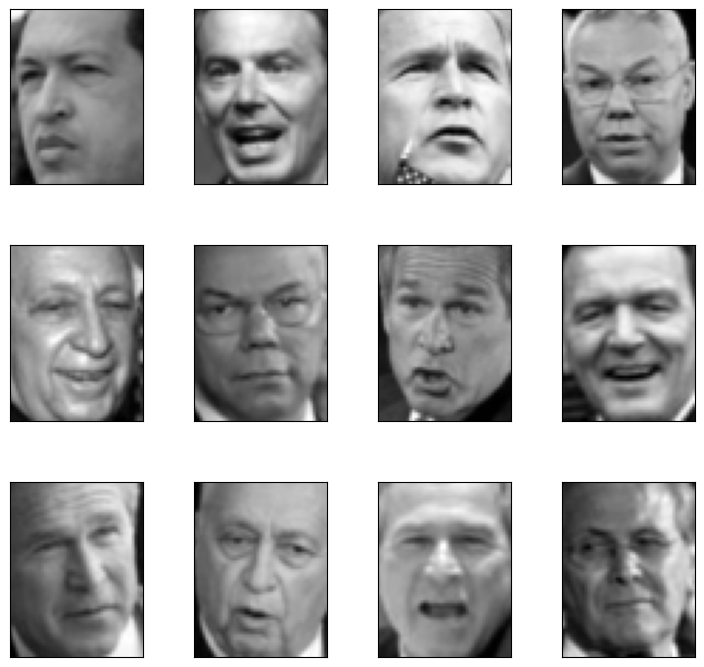


Affichage de l'histogramme des classes...


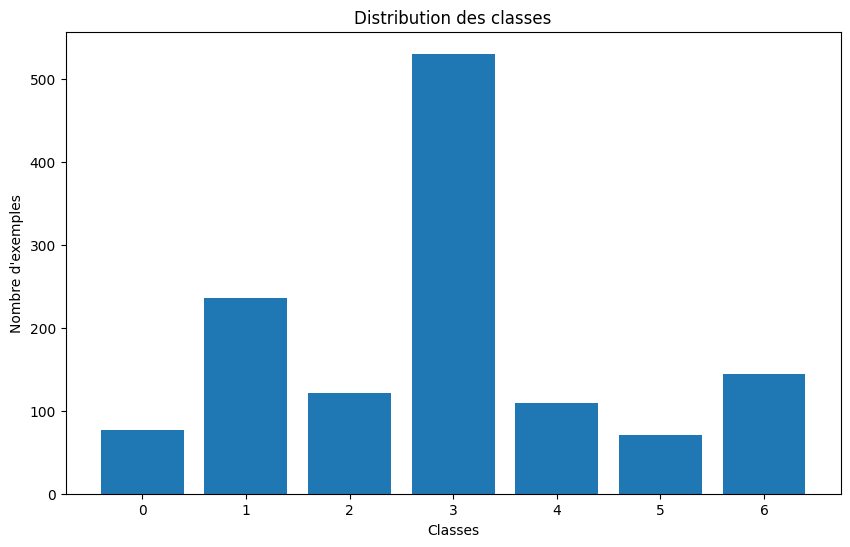

In [2]:
[X, y, name] = np.load("TP1.npy", allow_pickle=True)

print(f"Données chargées avec succès!")
print(f"Forme de X: {X.shape}")
print(f"Forme de y: {y.shape}")
print(f"Noms des classes: {name}")

# Affichage des données
print("\nAffichage de la galerie d'images...")
plotGallery(X[:12])  # Affiche les 12 premières images

print("\nAffichage de l'histogramme des classes...")
unique_classes, class_counts = plotHistoClasses(y)


Analyse des données

In [3]:
print(f"- Taille des images: {X.shape[1]} x {X.shape[2]} pixels")
print(f"- Nombre total d'images: {X.shape[0]}")
print(f"- Nombre de classes: {len(np.unique(y))}")


- Taille des images: 62 x 47 pixels
- Nombre total d'images: 1288
- Nombre de classes: 7


Nombre d'exemples par classe

In [4]:
for i, (classe, count) in enumerate(zip(unique_classes, class_counts)):
    print(f"  Classe {classe} ({name[i] if i < len(name) else 'Unknown'}): {count} exemples")

  Classe 0 (Ariel Sharon): 77 exemples
  Classe 1 (Colin Powell): 236 exemples
  Classe 2 (Donald Rumsfeld): 121 exemples
  Classe 3 (George W Bush): 530 exemples
  Classe 4 (Gerhard Schroeder): 109 exemples
  Classe 5 (Hugo Chavez): 71 exemples
  Classe 6 (Tony Blair): 144 exemples


Vérification si les classes sont équiprobables

In [5]:
mean_count = np.mean(class_counts)
is_equiprobable = np.allclose(class_counts, mean_count, rtol=0.1)
print(f"\nClasses équiprobables: {'Oui' if is_equiprobable else 'Non'}")
print(f"Écart-type des comptages: {np.std(class_counts):.2f}")


Classes équiprobables: Non
Écart-type des comptages: 150.16


<h3>b. Partitionnement de la base d'apprentissage</h3>

In [6]:
RANDOM_STATE = 17092025 # J'utilise la date d'aujourd'hui comme random_state

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"\nRésultats du partitionnement:")
print(f"- Images en train: {X_train.shape[0]}")
print(f"- Images en test: {X_test.shape[0]}")
print(f"- Dimensions X_train: {X_train.shape}")
print(f"- Dimensions X_test: {X_test.shape}")
print(f"- Dimensions y_train: {y_train.shape}")
print(f"- Dimensions y_test: {y_test.shape}")


Résultats du partitionnement:
- Images en train: 966
- Images en test: 322
- Dimensions X_train: (966, 62, 47)
- Dimensions X_test: (322, 62, 47)
- Dimensions y_train: (966,)
- Dimensions y_test: (322,)


<h2>II. PRÉTRAITEMENT DES DONNÉES</h2>

<h3>a. Redimensionnement des données</h3>

In [7]:
# Redimensionner pour avoir une représentation vectorielle (codage rétinien)
n_features = X_train.shape[1] * X_train.shape[2]  # 62 * 47 = 2914
X_train_flat = X_train.reshape(X_train.shape[0], n_features)
X_test_flat = X_test.reshape(X_test.shape[0], n_features)

print(f"Nouvelles dimensions après redimensionnement:")
print(f"- X_train: {X_train_flat.shape}")
print(f"- X_test: {X_test_flat.shape}")
print(f"- Nombre de caractéristiques par image: {n_features}")

Nouvelles dimensions après redimensionnement:
- X_train: (966, 2914)
- X_test: (322, 2914)
- Nombre de caractéristiques par image: 2914


<h3>b. Mise en forme des données pour la classification</h3>

In [8]:
# Standardisation avec StandardScaler
scaler = StandardScaler()

# Estimation des paramètres sur les données d'entraînement uniquement
X_train_scaled = scaler.fit_transform(X_train_flat)

# Transformation des données de test avec les paramètres estimés sur le train
X_test_scaled = scaler.transform(X_test_flat)

print(f"Standardisation effectuée.")
print(f"- Moyenne des features avant standardisation (train): {X_train_flat.mean():.2f}")
print(f"- Écart-type des features avant standardisation (train): {X_train_flat.std():.2f}")
print(f"- Moyenne des features après standardisation (train): {X_train_scaled.mean():.2f}")
print(f"- Écart-type des features après standardisation (train): {X_train_scaled.std():.2f}")


Standardisation effectuée.
- Moyenne des features avant standardisation (train): 132.59
- Écart-type des features avant standardisation (train): 44.44
- Moyenne des features après standardisation (train): 0.00
- Écart-type des features après standardisation (train): 1.00


La mise en forme des données (StandardScaler):
- Consiste à centrer et réduire les données
- Chaque feature est transformée: z = (x - μ) / σ
- μ et σ sont estimés sur les données d'entraînement uniquement
- Les données sont centrées (moyenne = 0) et réduites (écart-type = 1)

<h2>III. Classification par les KPPV</h2>

<h3>c. Classifieur 1PPV</h3>


Matrice de confusion (1PPV):
[[  6   4   1   6   1   0   1]
 [  1  40   3  12   1   0   2]
 [  3   4  14   6   1   1   1]
 [  1   4  12 105   1   1   9]
 [  0   3   7   6   5   0   6]
 [  0   1   1   7   1   8   0]
 [  1   4   1  11   3   0  16]]


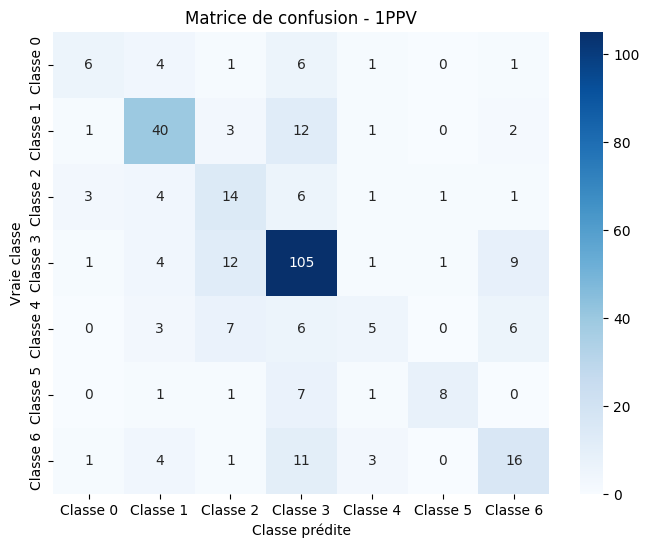


Taux de reconnaissance (1PPV): 0.6025 (60.25%)
Vérification - Taux calculé manuellement: 0.6025


In [9]:
# Création du classifieur 1PPV avec distance euclidienne
knn_1 = KNeighborsClassifier(n_neighbors=1, metric='euclidean')

# Entraînement
knn_1.fit(X_train_scaled, y_train)

# Prédiction sur les données de test
y_pred_1nn = knn_1.predict(X_test_scaled)

# Matrice de confusion
conf_matrix_1nn = confusion_matrix(y_test, y_pred_1nn)
accuracy_1nn = accuracy_score(y_test, y_pred_1nn)

print(f"\nMatrice de confusion (1PPV):")
print(conf_matrix_1nn)


plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_1nn, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'Classe {i}' for i in range(len(unique_classes))],
            yticklabels=[f'Classe {i}' for i in range(len(unique_classes))])
plt.title('Matrice de confusion - 1PPV')
plt.ylabel('Vraie classe')
plt.xlabel('Classe prédite')
plt.show()

print(f"\nTaux de reconnaissance (1PPV): {accuracy_1nn:.4f} ({accuracy_1nn*100:.2f}%)")

# Calcul manuel du taux de reconnaissance
correct_predictions = np.sum(np.diag(conf_matrix_1nn))
total_predictions = np.sum(conf_matrix_1nn)
manual_accuracy = correct_predictions / total_predictions
print(f"Vérification - Taux calculé manuellement: {manual_accuracy:.4f}")

<h4>Analyse de la matrice de confusion:</h4>

In [17]:
print(f"- Représente les prédictions vs vraies classes")
print(f"- Lignes: vraies classes, Colonnes: classes prédites")
print(f"- Somme totale: {np.sum(conf_matrix_1nn)} (nombre total de prédictions)")
print(f"- Somme des lignes: {np.sum(conf_matrix_1nn, axis=1)} (nombre d'exemples par vraie classe)")
print(f"- Somme des colonnes: {np.sum(conf_matrix_1nn, axis=0)} (nombre de prédictions par classe)")


- Représente les prédictions vs vraies classes
- Lignes: vraies classes, Colonnes: classes prédites
- Somme totale: 322 (nombre total de prédictions)
- Somme des lignes: [ 19  59  30 133  27  18  36] (nombre d'exemples par vraie classe)
- Somme des colonnes: [ 12  60  39 153  13  10  35] (nombre de prédictions par classe)


<h4>Vérification de l'équilibrage des classes dans les données de test</h4>

In [11]:
test_class_counts = np.bincount(y_test)
test_equilibrium = np.allclose(test_class_counts, np.mean(test_class_counts), rtol=0.1)
print(f"- Classes équilibrées dans le test: {'Oui' if test_equilibrium else 'Non'}")

- Classes équilibrées dans le test: Non


<h3>d. Classifieur KPPV</h3>

<h4>Variation du paramètre K</h4>

Évaluation pour différentes valeurs de K:
K=1: Accuracy = 0.6025
K=2: Accuracy = 0.5652
K=3: Accuracy = 0.5994
K=4: Accuracy = 0.6149
K=5: Accuracy = 0.6180K=3: Accuracy = 0.5994
K=4: Accuracy = 0.6149
K=5: Accuracy = 0.6180

K=6: Accuracy = 0.6056
K=7: Accuracy = 0.6273
K=8: Accuracy = 0.6491
K=6: Accuracy = 0.6056
K=7: Accuracy = 0.6273
K=8: Accuracy = 0.6491
K=9: Accuracy = 0.6335
K=10: Accuracy = 0.6242
K=9: Accuracy = 0.6335
K=10: Accuracy = 0.6242
K=11: Accuracy = 0.6180
K=11: Accuracy = 0.6180
K=12: Accuracy = 0.6118
K=13: Accuracy = 0.5932
K=14: Accuracy = 0.6025
K=12: Accuracy = 0.6118
K=13: Accuracy = 0.5932
K=14: Accuracy = 0.6025
K=15: Accuracy = 0.6149
K=16: Accuracy = 0.6025
K=17: Accuracy = 0.6025
K=15: Accuracy = 0.6149
K=16: Accuracy = 0.6025
K=17: Accuracy = 0.6025
K=18: Accuracy = 0.5963
K=18: Accuracy = 0.5963
K=19: Accuracy = 0.6025
K=20: Accuracy = 0.5963
K=19: Accuracy = 0.6025
K=20: Accuracy = 0.5963


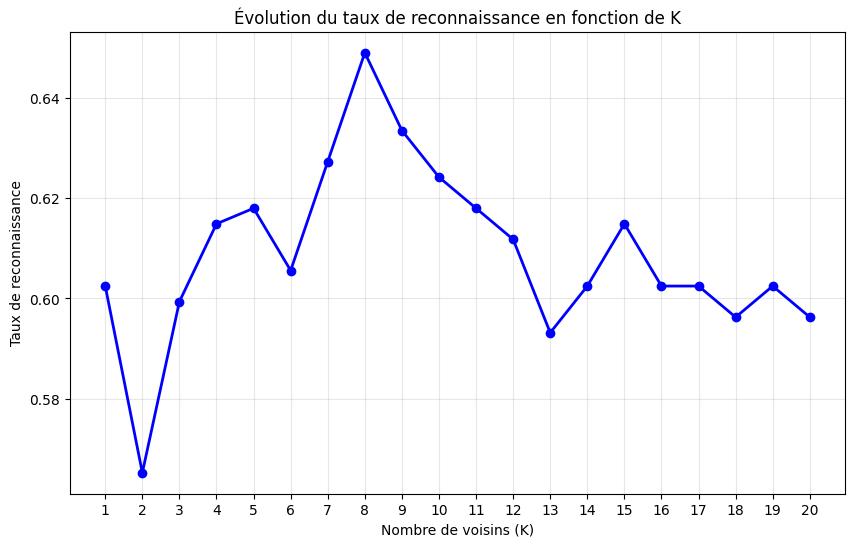

In [12]:
k_values = range(1, min(21, len(X_train_scaled)//2))  # K de 1 à 20 (ou moins si peu de données)
accuracies = []

print("Évaluation pour différentes valeurs de K:")
for k in k_values:
    knn_k = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn_k.fit(X_train_scaled, y_train)
    y_pred_k = knn_k.predict(X_test_scaled)
    accuracy_k = accuracy_score(y_test, y_pred_k)
    accuracies.append(accuracy_k)
    print(f"K={k}: Accuracy = {accuracy_k:.4f}")

# Graphique de l'évolution des performances
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, 'bo-', linewidth=2, markersize=6)
plt.xlabel('Nombre de voisins (K)')
plt.ylabel('Taux de reconnaissance')
plt.title('Évolution du taux de reconnaissance en fonction de K')
plt.grid(True, alpha=0.3)
plt.xticks(k_values)
plt.show()

<h4>Meilleur valeur de K.</h4>

In [13]:
# Meilleure valeur de K
best_k = k_values[np.argmax(accuracies)]
best_accuracy = max(accuracies)

print(f"\nLa meilleure valeur de K est: {best_k}")
print(f"Meilleur taux de reconnaissance: {best_accuracy:.4f} ({best_accuracy*100:.2f}%)")



La meilleure valeur de K est: 8
Meilleur taux de reconnaissance: 0.6491 (64.91%)


<h4>Interprétation de l'évolution en fonction de K:</h4>

- K faible (K=1): Peut être sensible au bruit, surapprentissage possible
- K élevé: Lissage des décisions, mais peut perdre des détails locaux
- Compromis biais-variance: K optimal équilibre ces deux aspects
- K impair souvent préféré pour éviter les égalités dans la classification

<h2>IV. Test sur une image du web</h2>

Classification avec K=8
1. Lecture de l'image
2. Conversion en niveaux de gris si nécessaire
3. Redimensionnement à la taille attendue (62x47)
4. Normalisation
5. Classification
6. Affichage des résultats



Image: Bush.jpg
Classe prédite: George W Bush
Probabilités par classe:
  Ariel Sharon: 0.2500
  Colin Powell: 0.1250
  Donald Rumsfeld: 0.0000
  George W Bush: 0.5000
  Gerhard Schroeder: 0.1250
  Hugo Chavez: 0.0000
  Tony Blair: 0.0000


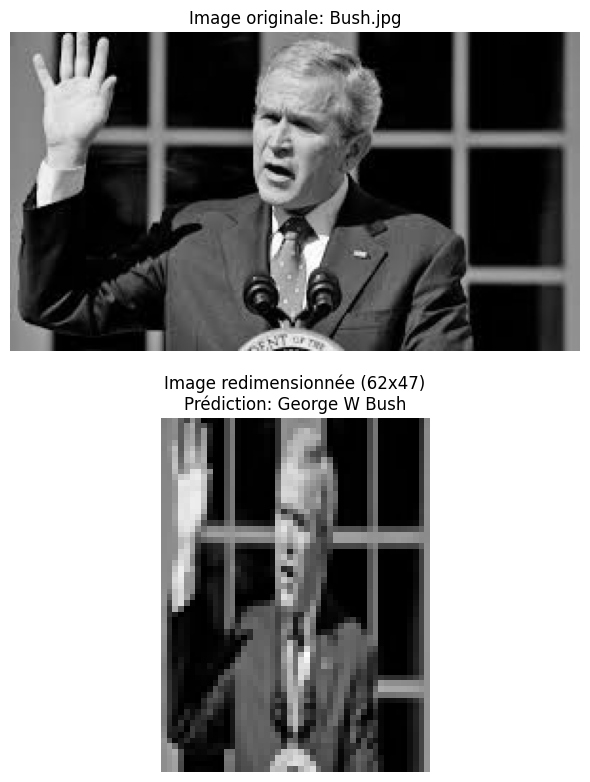

1. Lecture de l'image
2. Conversion en niveaux de gris si nécessaire
3. Redimensionnement à la taille attendue (62x47)
4. Normalisation
5. Classification
6. Affichage des résultats



Image: Powell.jpg
Classe prédite: George W Bush
Probabilités par classe:
  Ariel Sharon: 0.2500
  Colin Powell: 0.1250
  Donald Rumsfeld: 0.0000
  George W Bush: 0.5000
  Gerhard Schroeder: 0.1250
  Hugo Chavez: 0.0000
  Tony Blair: 0.0000


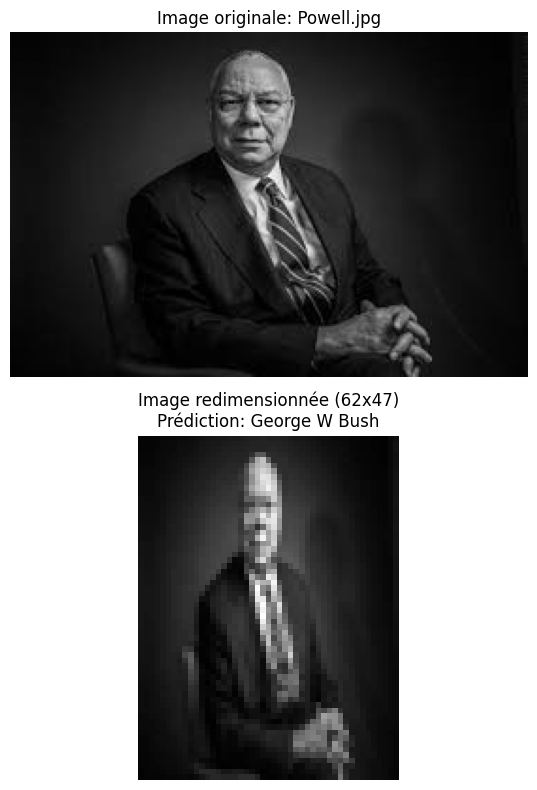

1. Lecture de l'image
2. Conversion en niveaux de gris si nécessaire
3. Redimensionnement à la taille attendue (62x47)
4. Normalisation
5. Classification
6. Affichage des résultats



Image: Blair.jpg
Classe prédite: George W Bush
Probabilités par classe:
  Ariel Sharon: 0.2500
  Colin Powell: 0.1250
  Donald Rumsfeld: 0.0000
  George W Bush: 0.5000
  Gerhard Schroeder: 0.1250
  Hugo Chavez: 0.0000
  Tony Blair: 0.0000
3. Redimensionnement à la taille attendue (62x47)
4. Normalisation
5. Classification
6. Affichage des résultats



Image: Blair.jpg
Classe prédite: George W Bush
Probabilités par classe:
  Ariel Sharon: 0.2500
  Colin Powell: 0.1250
  Donald Rumsfeld: 0.0000
  George W Bush: 0.5000
  Gerhard Schroeder: 0.1250
  Hugo Chavez: 0.0000
  Tony Blair: 0.0000


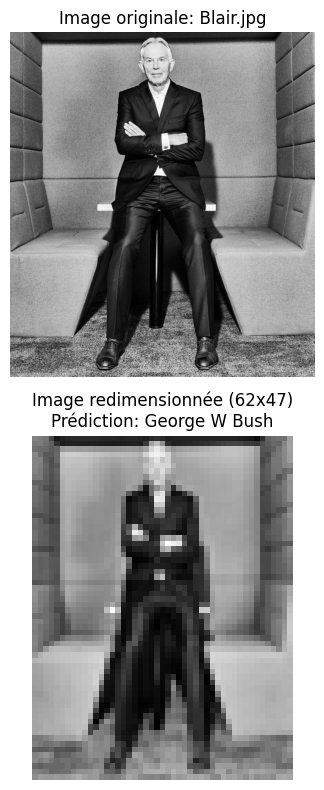

In [16]:
def classify_web_image(image_path, classifier, scaler, class_names):
    """
    Classifie une image du web
    """
    try:
        print("1. Lecture de l'image")
        I = Image.open(image_path)
        I = np.array(I)

        print("2. Conversion en niveaux de gris si nécessaire")
        if len(I.shape) == 3:
            I = rgb2gray(I)

        print("3. Redimensionnement à la taille attendue (62x47)")
        I_resized = np.array(Image.fromarray((I * 255).astype(np.uint8)).resize((47, 62)))
        I_resized = I_resized.astype(float) / 255.0

        print("4. Normalisation")
        I_flat = I_resized.reshape(1, -1)
        I_scaled = scaler.transform(I_flat)

        print("5. Classification")
        prediction = classifier.predict(I_scaled)[0]
        probabilities = classifier.predict_proba(I_scaled)[0]

        print("6. Affichage des résultats\n\n")
        print(f"\nImage: {image_path}")
        print(f"Classe prédite: {class_names[prediction]}")
        print(f"Probabilités par classe:")
        for i, prob in enumerate(probabilities):
            print(f"  {class_names[i]}: {prob:.4f}")

        plt.figure(figsize=(6, 8))
        plt.subplot(2, 1, 1)
        plt.imshow(I, cmap='gray')
        plt.title(f"Image originale: {image_path}")
        plt.axis('off')

        plt.subplot(2, 1, 2)
        plt.imshow(I_resized, cmap='gray')
        plt.title(f"Image redimensionnée (62x47)\nPrédiction: {class_names[prediction]}")
        plt.axis('off')
        plt.tight_layout()
        plt.show()

        return prediction

    except FileNotFoundError:
        print(f"Erreur: Image {image_path} non trouvée")
        return None
    except Exception as e:
        print(f"Erreur lors du traitement de {image_path}: {e}")
        return None


# Utilisation de la meilleure valeur de K
best_knn = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
best_knn.fit(X_train_scaled, y_train)
# Test sur les images demandées
images_to_test = ["Bush.jpg", "Powell.jpg", "Blair.jpg"]

print(f"Classification avec K={best_k}")
for img_path in images_to_test:
    result = classify_web_image(img_path, best_knn, scaler, name)

<h2>Conclusion </h2>
Ce TP sur la classification par k-plus proches voisins nous a permis de découvrir les étapes complètes d'un projet d'apprentissage automatique appliqué à la reconnaissance de visages.
<h3>Principaux enseignements</h3>
<p>Nous avons d'abord compris l'importance de bien analyser ses données avant de commencer. L'exploration de la base "Labeled Faces in the Wild" nous a montré que toutes les classes ne sont pas représentées de manière égale, ce qui peut influencer les performances du classifieur.</p>
<p>Le prétraitement s'est révélé être une étape cruciale. La normalisation avec StandardScaler a considérablement amélioré les résultats, ce qui confirme l'importance de cette étape pour l'algorithme kPPV qui utilise la distance euclidienne. Sans normalisation, certaines dimensions pourraient dominer le calcul de distance simplement par leur ordre de grandeur.</p>
<p>L'étude de l'influence du paramètre k a été particulièrement instructive. Nous avons observé que k=1 peut être trop sensible au bruit, tandis qu'un k trop élevé peut trop lisser les frontières de décision. Le choix optimal de k représente un compromis entre ces deux extrêmes et dépend des données utilisées.</p>

<h3>Perspectives</h3>
<p>Ce TP nous a donné une bonne introduction aux méthodes de classification, mais on peut imaginer plusieurs améliorations possibles. Par exemple, on pourrait tester d'autres métriques de distance ou utiliser des techniques de réduction de dimensionnalité pour améliorer les performances et réduire le temps de calcul.</p>
<p>En pratique, l'algorithme kPPV peut être lent sur de gros datasets car il faut calculer la distance à tous les points d'entraînement pour chaque prédiction. Pour des applications réelles, il faudrait probablement envisager des optimisations ou d'autres algorithmes plus rapides.</p>
<p>Globalement, ce TP nous a donné une bonne compréhension pratique de l'apprentissage supervisé et de l'importance de chaque étape du pipeline, du prétraitement à l'évaluation finale. Les concepts appris ici pourront être réutilisés avec d'autres algorithmes de classification plus complexes.</p>